# 07 Support Vector Machines (SVM)

In [2]:
# Core Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and Statistical Methods
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.svm import SVC


In [39]:
from sklearn import datasets
iris = datasets.load_iris()

df = pd.DataFrame(iris["data"], columns=iris.feature_names)
df["species"] = iris.target_names[iris.target]


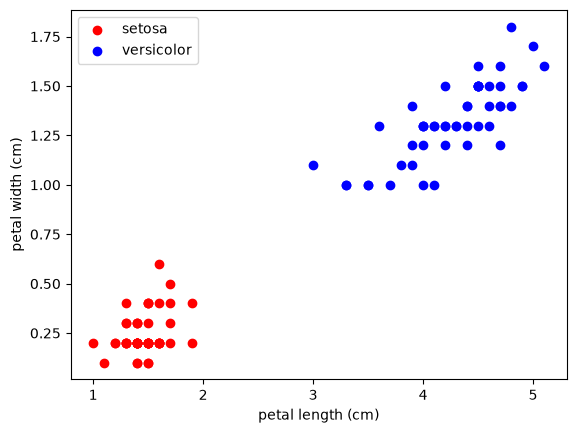

In [40]:
df_two_species = df[(df["species"]=="versicolor") | (df["species"]=="setosa")]
plt.scatter(df_two_species[df_two_species["species"]=="setosa"][["petal length (cm)"]],
            df_two_species[df_two_species["species"]=="setosa"][["petal width (cm)"]],
           color="r",
           label="setosa")

plt.scatter(df_two_species[df_two_species["species"]=="versicolor"][["petal length (cm)"]],
            df_two_species[df_two_species["species"]=="versicolor"][["petal width (cm)"]],
           color="b",
           label="versicolor")

plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.legend()
plt.show()

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.svm import SVC

iris = load_iris()

# Use two features so we can visualize the boundary
X = iris.data[:, [2, 3]]   # petal length, petal width
y = iris.target

# Train SVM
svm_clf = SVC(kernel="linear", C=1)
svm_clf.fit(X, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [24]:
x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 500),
    np.linspace(x2_min, x2_max, 500)
)

In [25]:
grid = np.c_[xx.ravel(), yy.ravel()]

Z = svm_clf.predict(grid)

Z = Z.reshape(xx.shape)

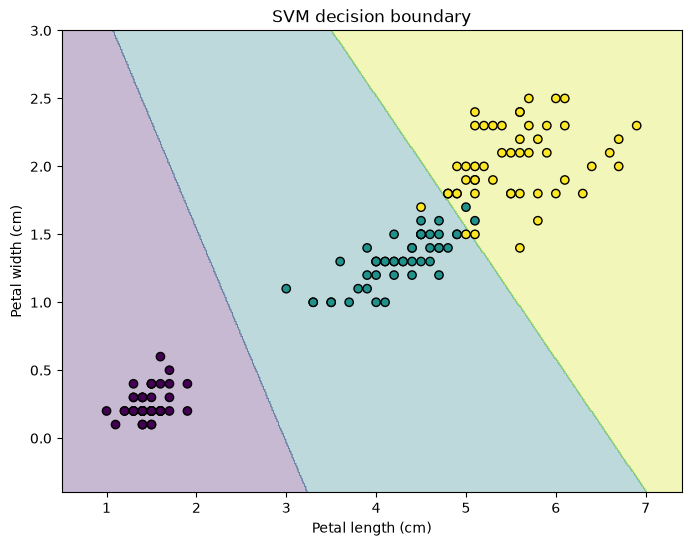

In [26]:
plt.figure(figsize=(8, 6))

# Decision regions
plt.contourf(xx, yy, Z, alpha=0.3)

# Actual Iris observations
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    edgecolors="k"
)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("SVM decision boundary")

plt.show()